# Quantum Phase Estimation (QPE)

Quantum Phase Estimation is a quantum algorithm used to estimate the phase associated with an eigenvector of a unitary operator.

It can solve problems such as finding eigenvalues of unitary matrices and simulating quantum systems.

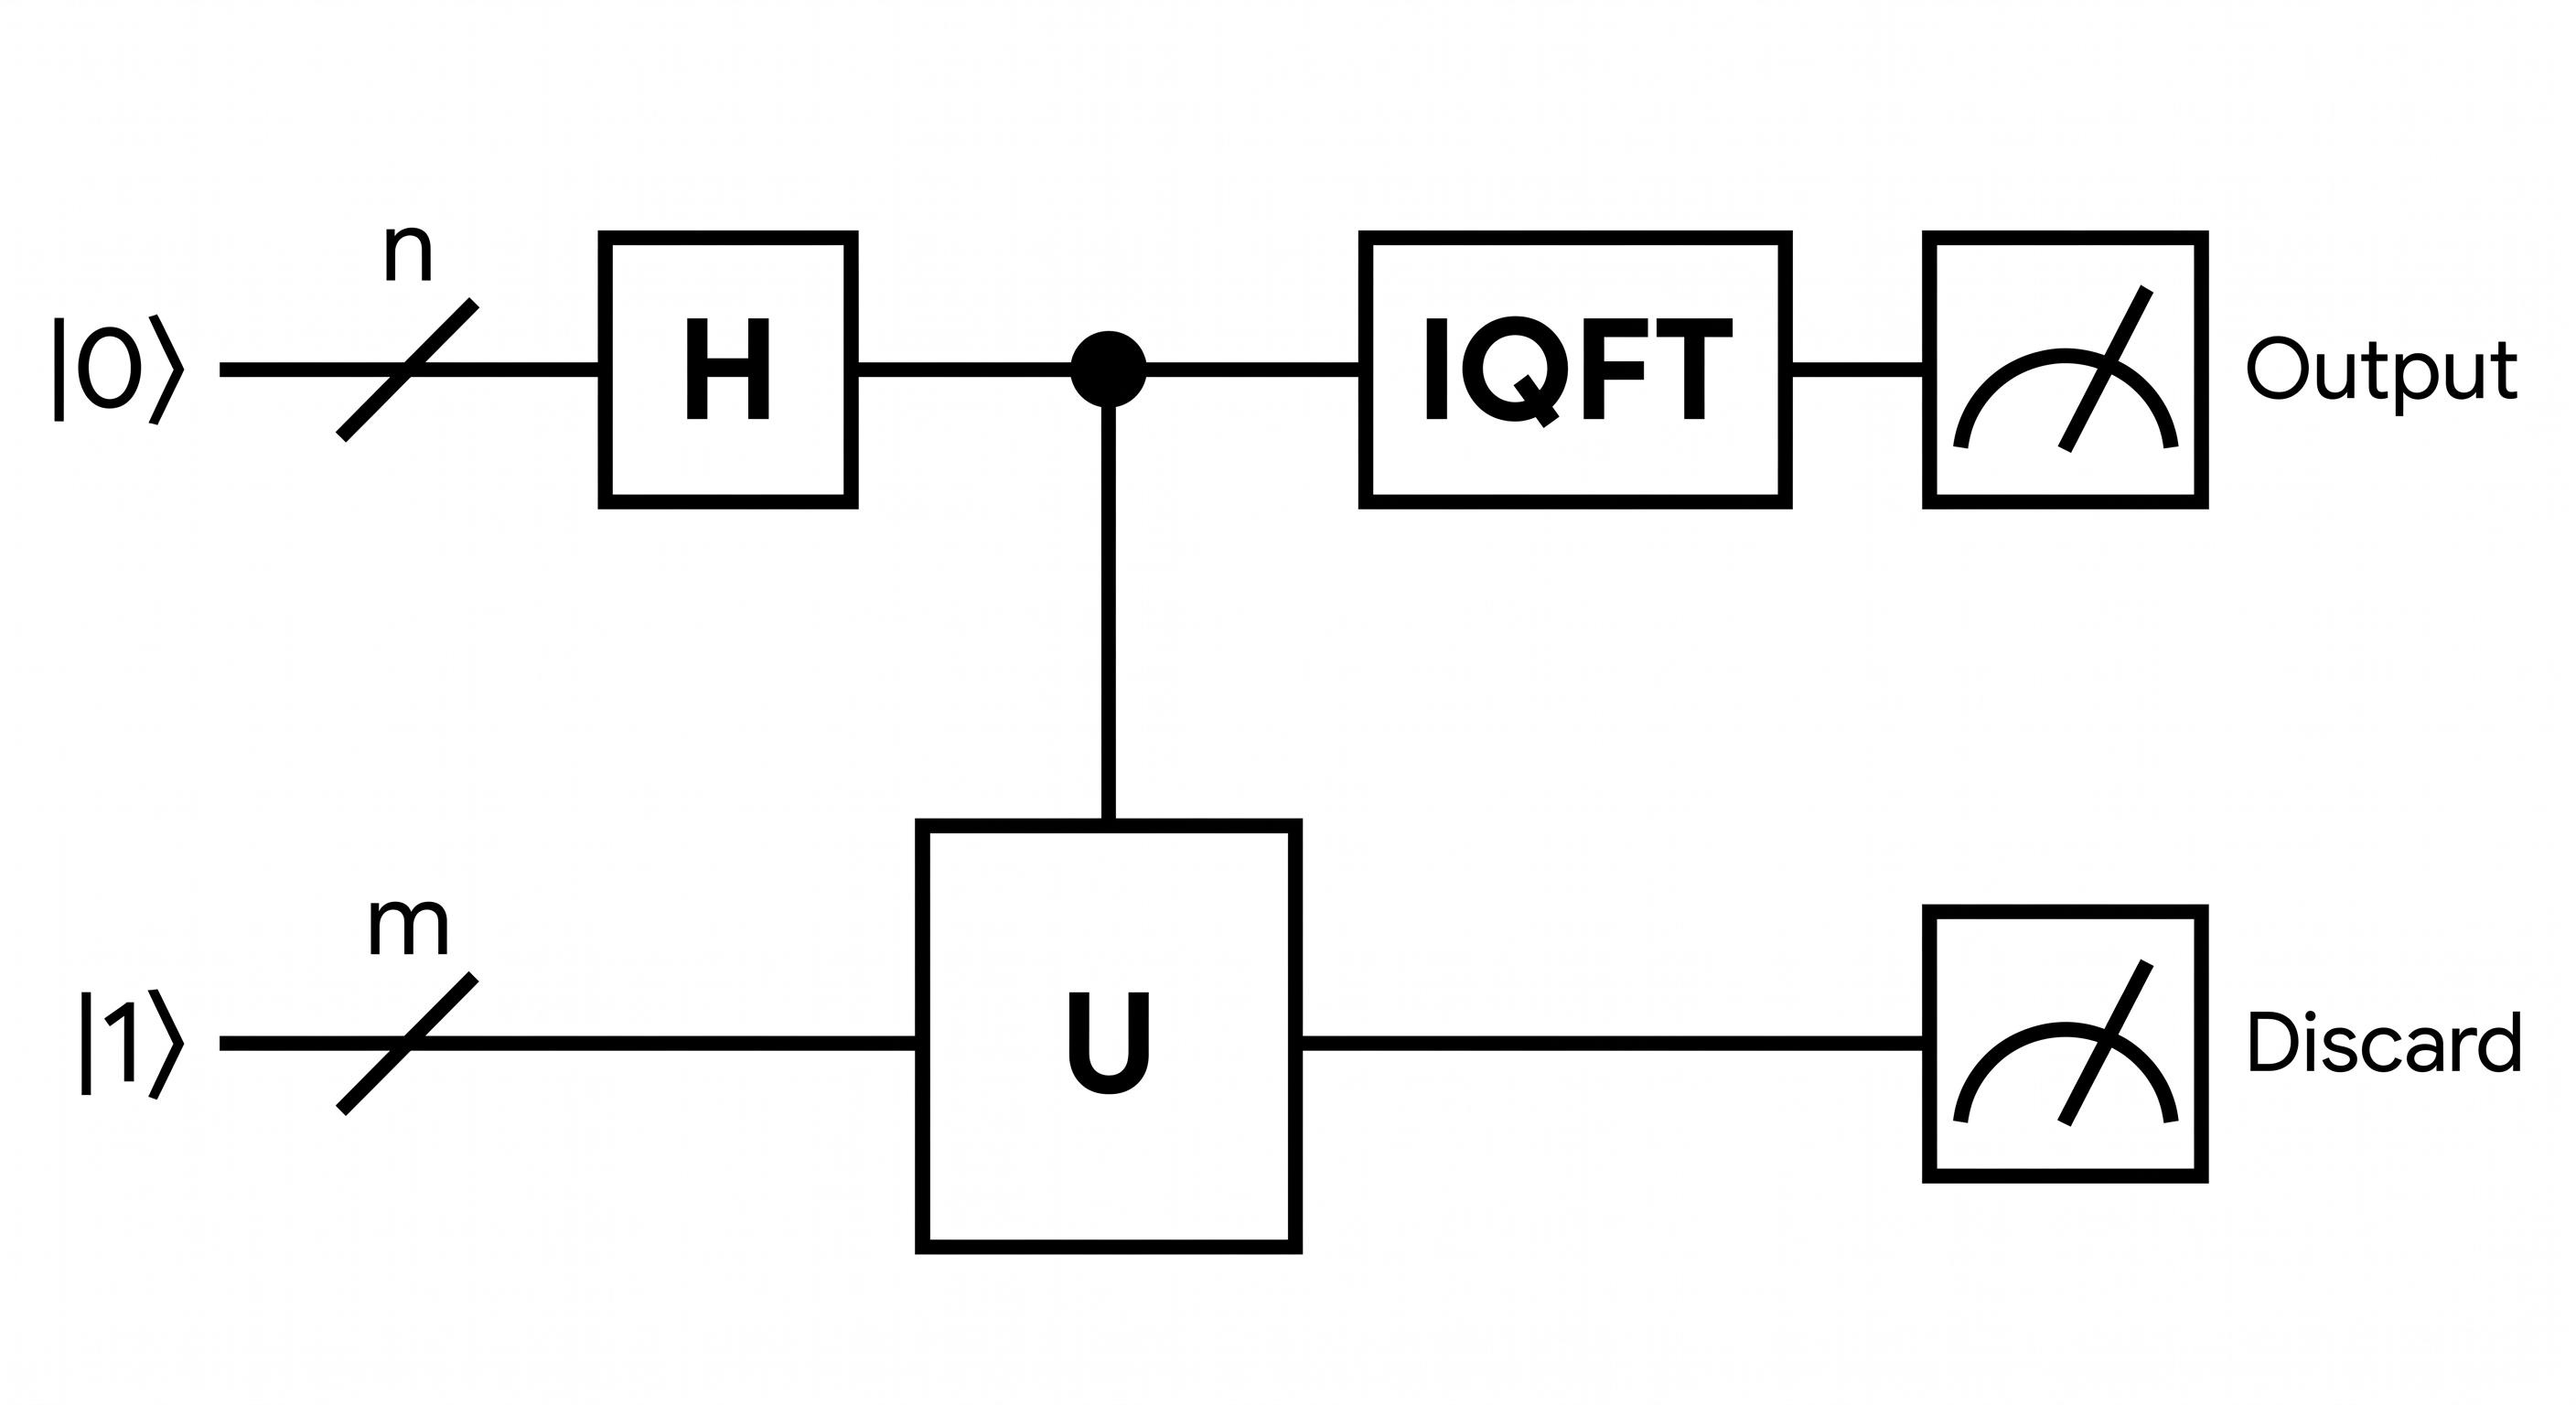

**Process:**
1. Prepare one set of qubit register and another set of n-qubit counting register
2. Create uniform superposition by applying Hadamard gate $H$ to every qubit in the $n$-qubit counting register
3. For each counting qubit, Apply controlled unitaries (phase kickback)
4. Apply the inverse quantum Fourier transform to the counting register to convert the phase-encoded Fourier basis back into the computational (Z) basis
5. Measure the $n$ counting qubits in the computational basis to obtain an integer outcome $y \in \{0, 1, \dots, 2^n - 1\}$, giving the phase estimate:$$\hat{\theta} = \frac{y}{2^n}$$

In [1]:
from numpy import pi
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.library import QFTGate
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_bloch_multivector
from qiskit.quantum_info import Statevector

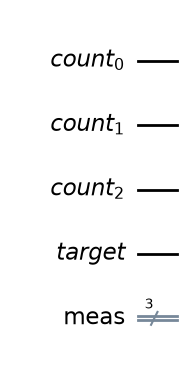

In [2]:
# Parameters and named registers

n_count = 3
theta = 1/8  # Eigenphase of T gate on |1> is 1/8

counting = QuantumRegister(n_count, "count")
target = QuantumRegister(1, "target")
c_out = ClassicalRegister(n_count, "meas")

qc = QuantumCircuit(counting, target, c_out)

qc.draw("mpl")

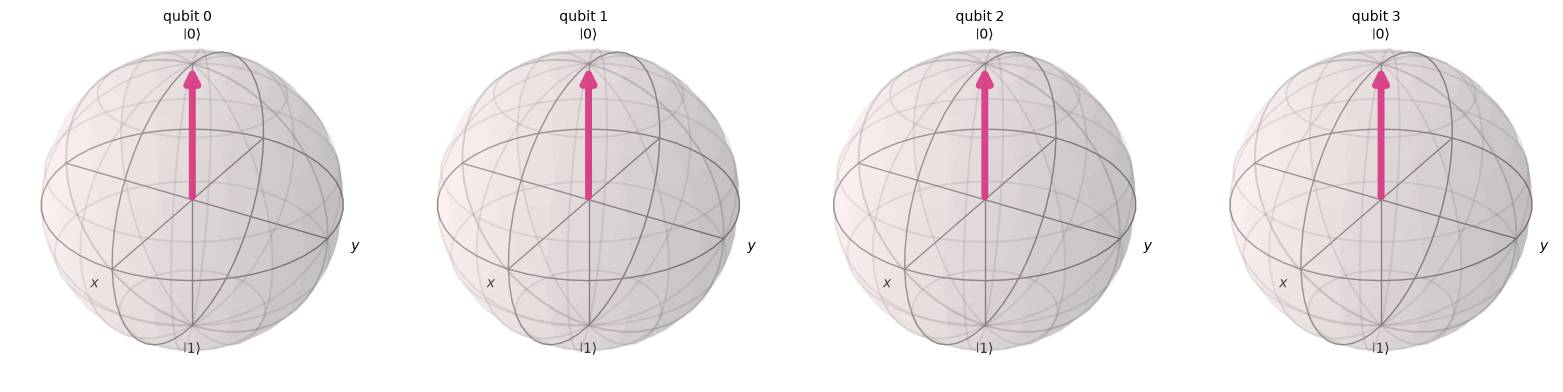

In [3]:
statevector = Statevector(qc)
plot_bloch_multivector(statevector)

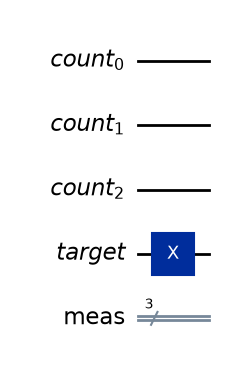

In [4]:
# Prepare eigenstate - apply H on target

qc.x(target[0])

qc.draw("mpl")

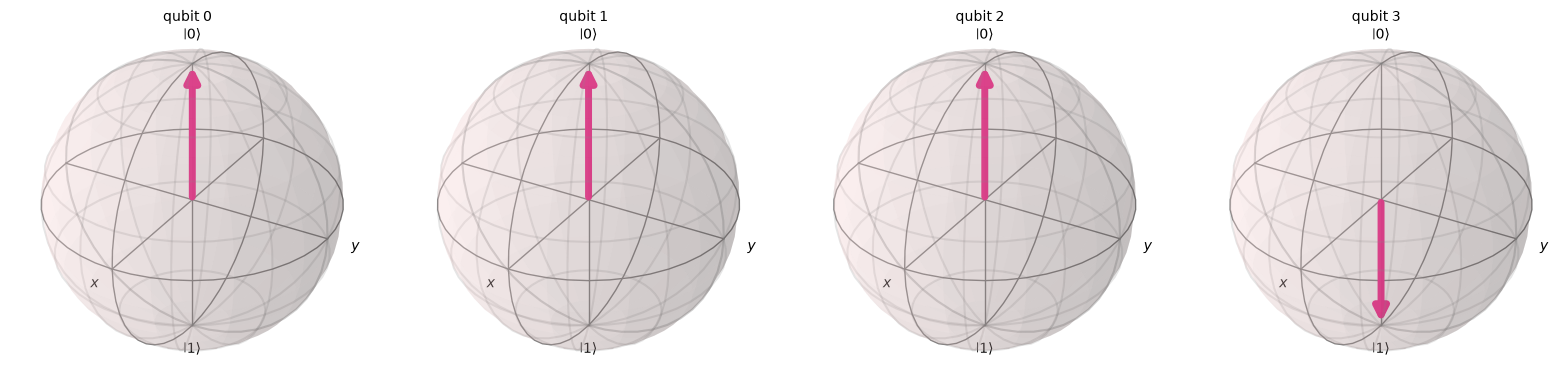

In [5]:
statevector = Statevector(qc)
plot_bloch_multivector(statevector)

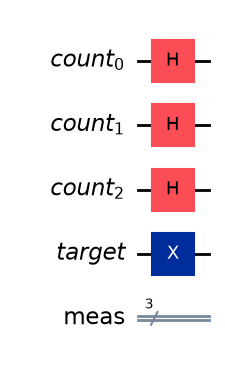

In [6]:
# Apply Hadamard gates to the counting qubits

for qubit in counting:
    qc.h(qubit)

qc.draw("mpl")

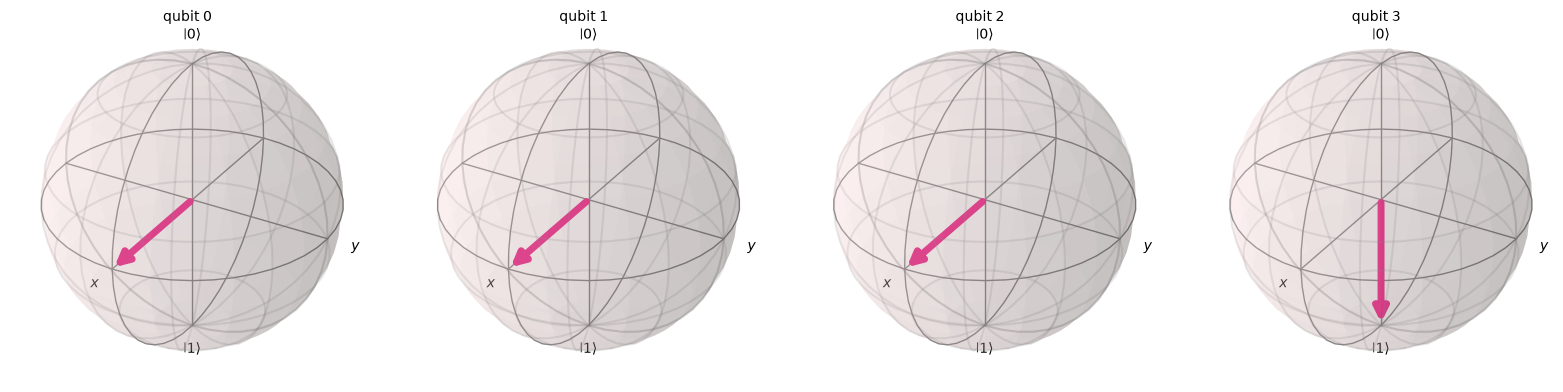

In [7]:
plot_bloch_multivector(Statevector(qc))

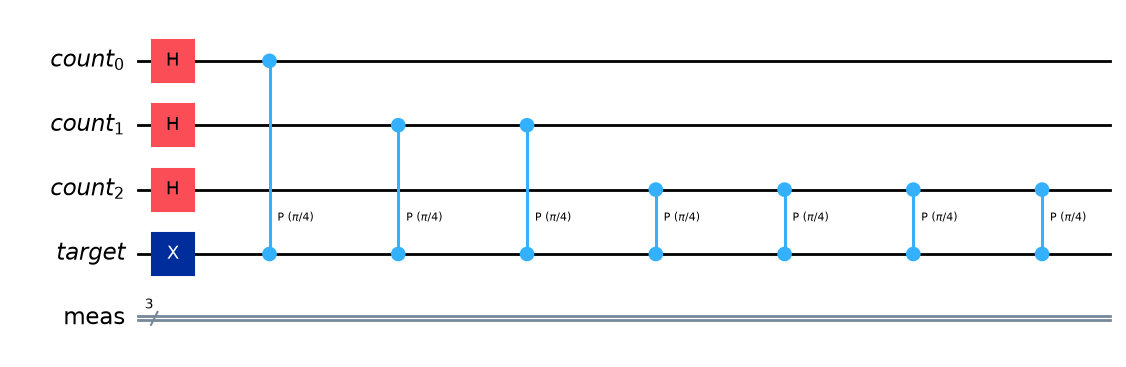

In [8]:
# Perform controlled unitary operation - Phase Kickback

for j, q in enumerate(counting):
  repetitions = 2**j
  for _ in range(repetitions):
    qc.cp(2 * pi * theta, q, target[0])

qc.draw("mpl")

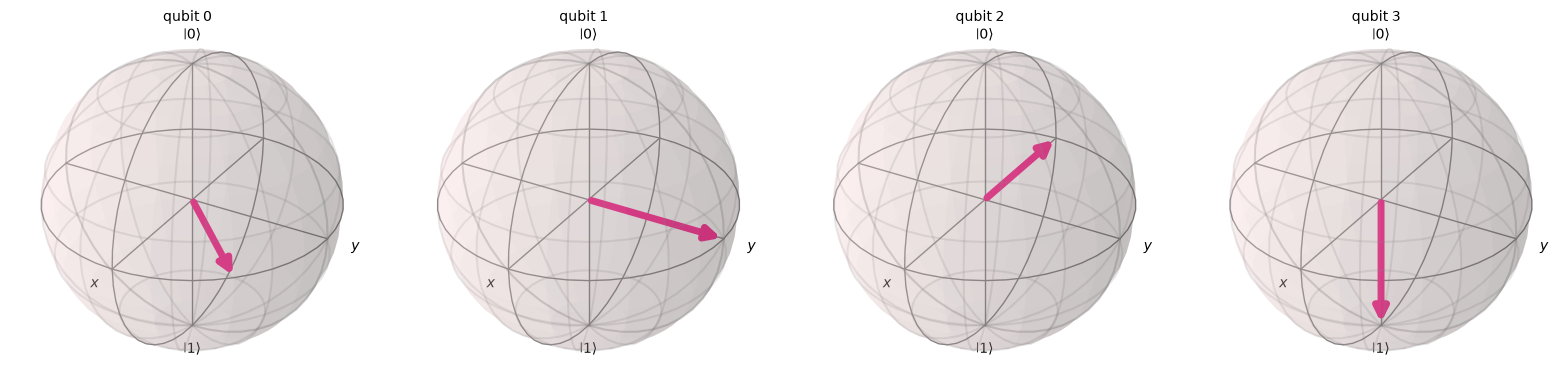

In [9]:
plot_bloch_multivector(Statevector(qc))

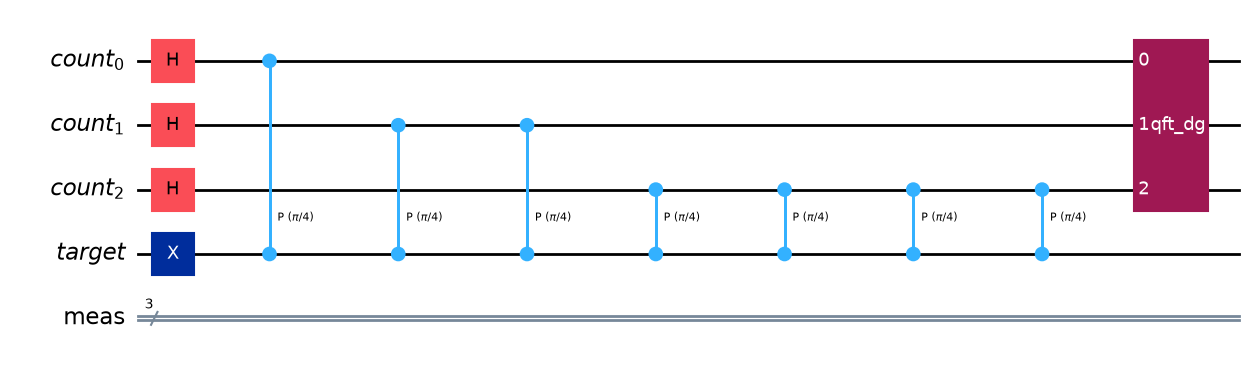

In [10]:
# Apply the inverse quantum Fourier transformation to convert the state of the counting register

iqft = QFTGate(n_count).inverse()
qc.append(iqft, counting)

# Decompose composite gates so qc.draw("mpl") shows the gate structure cleanly
qc.draw("mpl")

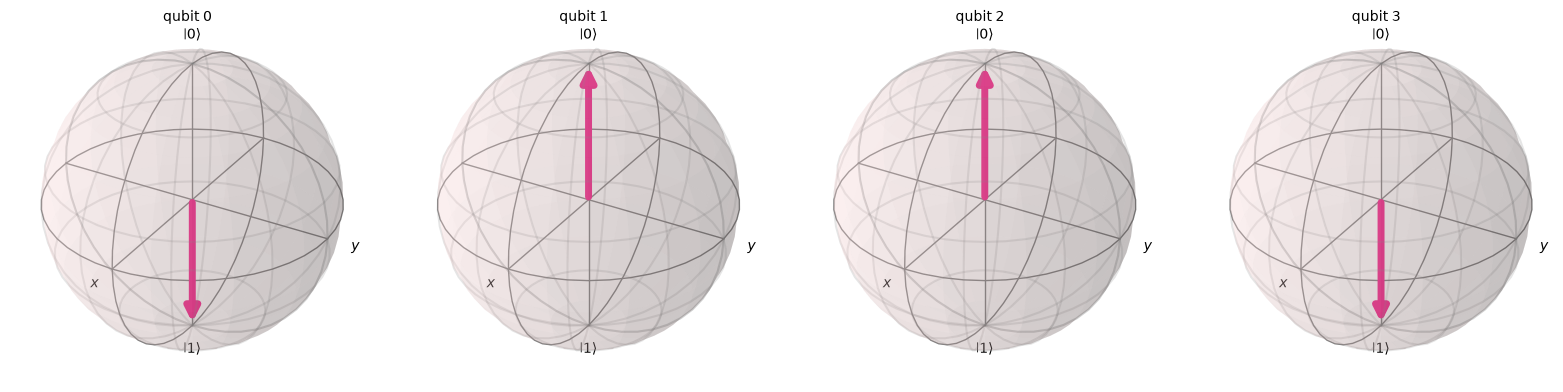

In [11]:
plot_bloch_multivector(Statevector(qc))

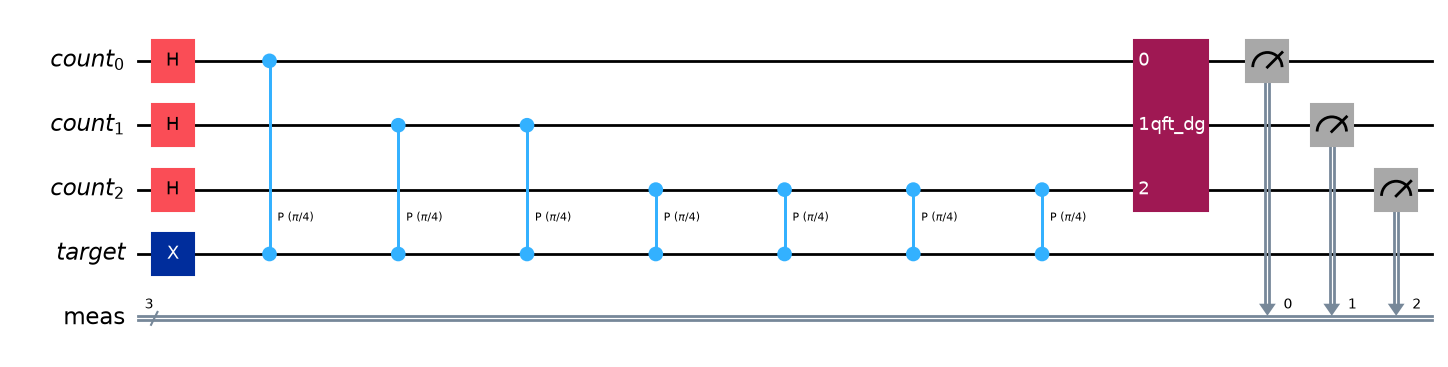

In [12]:
# Measure

qc.measure(counting, c_out)

qc.draw("mpl")

Counts: {'001': 2048}
Top bitstring: 001 -> theta = 0.125


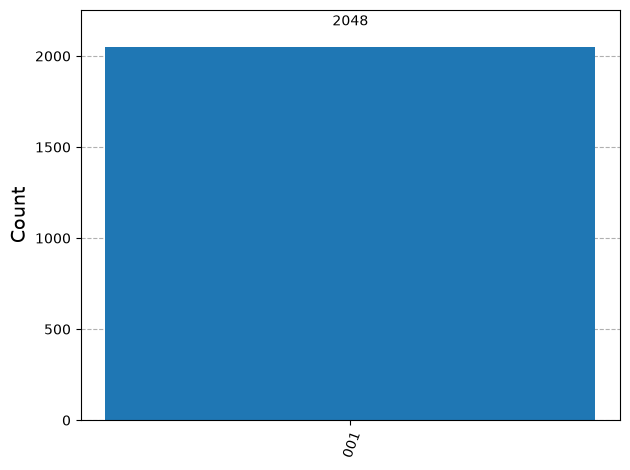

In [13]:
from qiskit.visualization import plot_histogram

aer_sim = AerSimulator()
shots = 2048

# Expand composite gates like qft_dg before running on AerSimulator
qc_sim = qc.decompose(reps=3)

result = aer_sim.run(qc_sim, shots=shots).result()
counts = result.get_counts()

print("Counts:", counts)

top_bitstring = max(counts, key=counts.get)
estimated_theta = int(top_bitstring, 2) / (2**n_count)

print(f"Top bitstring: {top_bitstring} -> theta = {estimated_theta}")

plot_histogram(counts)

Here we got 001 => 1

Now divide it with 2^n to get thita

1/2^3 = 1/8